# KMEANS — Cosine


In [ ]:
import time
import tracemalloc
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler, Normalizer
from sklearn_extra.cluster import KMedoids

default_data = next(
    (path for path in (Path("data/cafes.csv"), Path("cafes.csv")) if path.is_file()),
    Path("data/cafes.csv"),
)
DATA_PATH = Path(globals().get("DATA_PATH", default_data)).expanduser().resolve()
FIGURES_DIR = Path(globals().get("FIGURES_DIR", Path("reports/figures"))).expanduser().resolve()
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"CSV tidak ditemukan: {DATA_PATH}. Buka notebook dari folder paket "
        "atau tentukan DATA_PATH ke lokasi CSV Anda."
    )
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


In [ ]:
# ==============================================================================
# BAGIAN A: LOAD DATA & PREPROCESSING (MURNI FITUR NUMERIK KAFE)
# ==============================================================================
print("\n" + "="*56)
print("  BAGIAN A: LOAD DATA & PREPROCESSING")
print("="*56)

df = pd.read_csv(DATA_PATH, on_bad_lines="skip")

# Kolom fitur numerik kafe
kolom_fitur = ['latitude', 'longitude', 'rating', 'review_count']
kolom_ada = [k for k in kolom_fitur if k in df.columns]

# Ambil kolom numerik dan hapus baris bernilai kosong
df_fitur = df[kolom_ada].dropna()

# Standarisasi data dengan StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_fitur)

# Normalisasi L2 untuk Cosine distance
normalizer = Normalizer(norm='l2')
X_l2 = normalizer.fit_transform(X_scaled)

print(f"Data siap | Fitur: {kolom_ada}")
print(f"Bentuk Matriks (Shape): {X_scaled.shape} | Baris Sampel: {len(df_fitur)}")



  BAGIAN A: LOAD DATA & PREPROCESSING
Data siap | Fitur: ['latitude', 'longitude', 'rating', 'review_count']
Bentuk Matriks (Shape): (215, 4) | Baris Sampel: 215



  BAGIAN B: ELBOW METHOD (K=2 HINGGA 10)


e:\Master\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
e:\Master\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
e:\Master\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
e:\Master\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when the

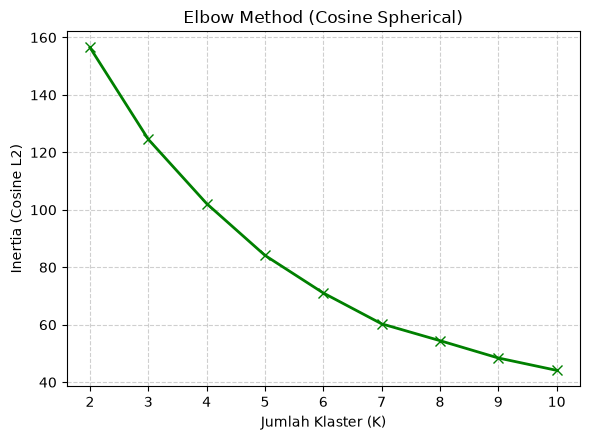

Grafik Elbow disimpan ke: E:\Code\machine_learning\uts\reports\figures\kmeans_cosine_elbow_plots.png


In [ ]:
# ==============================================================================
# BAGIAN B: ELBOW METHOD (UNTUK MENENTUKAN K TERBAIK)
# ==============================================================================
print("\n" + "="*56)
print("  BAGIAN B: ELBOW METHOD (K=2 HINGGA 10)")
print("="*56)

K_range = range(2, 11)

# 3. Elbow Cosine (L2 Normalizer + KMeans)
sse_cosine = []
for k in K_range:
    km_c = KMeans(n_clusters=k, random_state=42, n_init=10)
    km_c.fit(X_l2)
    sse_cosine.append(km_c.inertia_)


plt.figure(figsize=(6, 4.5))
plt.plot(list(K_range), sse_cosine, 'gx-', linewidth=2, markersize=7)
plt.xlabel('Jumlah Klaster (K)')
plt.ylabel('Inertia (Cosine L2)')
plt.title('Elbow Method (Cosine Spherical)')
plt.xticks(list(K_range))
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
elbow_plot_path = FIGURES_DIR / "kmeans_cosine_elbow_plots.png"
plt.savefig(elbow_plot_path, dpi=150)
plt.show()
plt.close()
print(f"Grafik Elbow disimpan ke: {elbow_plot_path}")

# Nilai K terbaik
K_TERBAIK_COS = 4


In [4]:
# --- 3. K-MEANS COSINE ---
print("\n" + "="*56)
print("  K-MEANS — METRIK: COSINE (L2-NORMALIZED)")
print("="*56)
tracemalloc.start()
t_mulai = time.time()

km_cosine = KMeans(n_clusters=K_TERBAIK_COS, random_state=42, n_init=10)
lbl_cosine = km_cosine.fit_predict(X_l2)

t_selesai = time.time()
_, mem_puncak = tracemalloc.get_traced_memory()
tracemalloc.stop()

sil_cosine = silhouette_score(X_l2, lbl_cosine, metric='cosine')
waktu_cos = t_selesai - t_mulai
mem_cos_kb = mem_puncak / 1024
mem_cos_mb = mem_puncak / (1024**2)

print(f"  Jumlah Klaster    : {K_TERBAIK_COS}")
print(f"  Waktu Eksekusi    : {waktu_cos:.4f} detik")
print(f"  Memori Puncak     : {mem_cos_kb:.2f} KB ({mem_cos_mb:.4f} MB)")
print(f"  Silhouette Score  : {sil_cosine:.4f}")
print("="*56)



  K-MEANS — METRIK: COSINE (L2-NORMALIZED)
  Jumlah Klaster    : 4
  Waktu Eksekusi    : 0.0890 detik
  Memori Puncak     : 191.60 KB (0.1871 MB)
  Silhouette Score  : 0.4377


e:\Master\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(



  BAGIAN D: VISUALISASI PCA 2D (K-MEANS)


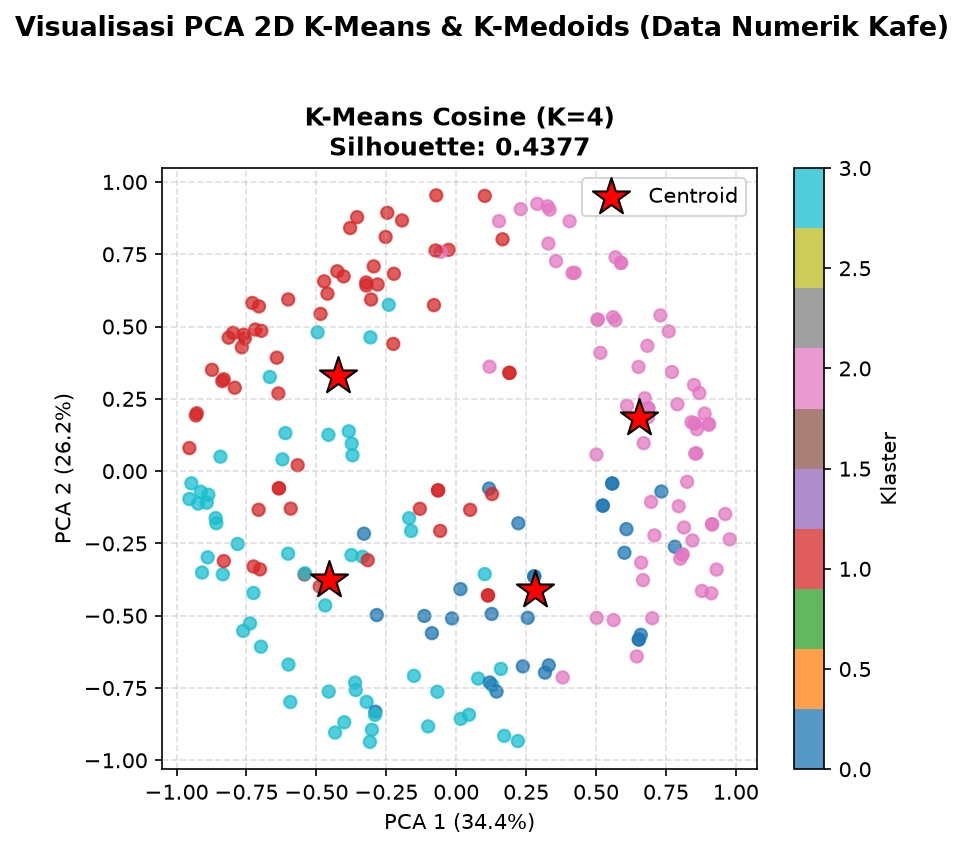

Visualisasi PCA disimpan ke: E:\Code\machine_learning\uts\reports\figures\kmeans_cosine_pca_plots.png


In [5]:
# ==============================================================================
# BAGIAN D: VISUALISASI PCA 2D DENGAN CENTROID BINTANG MERAH
# ==============================================================================
print("\n" + "="*56)
print("  BAGIAN D: VISUALISASI PCA 2D (K-MEANS)")
print("="*56)

pca_l2 = PCA(n_components=2, random_state=42)
X_pca_l2 = pca_l2.fit_transform(X_l2)
v1_l2, v2_l2 = pca_l2.explained_variance_ratio_ * 100

fig, ax = plt.subplots(figsize=(6, 5.5), dpi=150)
axes = [ax]
# 3. Plot Cosine
cen_c = pca_l2.transform(km_cosine.cluster_centers_)
sc3 = axes[0].scatter(X_pca_l2[:, 0], X_pca_l2[:, 1], c=lbl_cosine, cmap='tab10', s=35, alpha=0.75)
axes[0].scatter(cen_c[:, 0], cen_c[:, 1], c='red', marker='*', s=350, zorder=5, label='Centroid', edgecolors='black')
axes[0].set_title(f"K-Means Cosine (K={K_TERBAIK_COS})\nSilhouette: {sil_cosine:.4f}", fontweight='bold')
axes[0].set_xlabel(f'PCA 1 ({v1_l2:.1f}%)')
axes[0].set_ylabel(f'PCA 2 ({v2_l2:.1f}%)')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.4)
plt.colorbar(sc3, ax=axes[0], label='Klaster')

plt.suptitle("Visualisasi PCA 2D K-Means & K-Medoids (Data Numerik Kafe)", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
pca_plot_path = FIGURES_DIR / "kmeans_cosine_pca_plots.png"
plt.savefig(pca_plot_path, dpi=150, bbox_inches='tight')
plt.show()
plt.close()
print(f"Visualisasi PCA disimpan ke: {pca_plot_path}")


In [6]:
# Dictionary ringkasan performa untuk pelaporan
KMEANS_SUMMARY = {
    "cosine": {
        "algo": "K-Means", "metric": "Cosine", "param": f"K={K_TERBAIK_COS}",
        "time": waktu_cos, "mem_mb": mem_cos_mb, "clusters": K_TERBAIK_COS,
        "noise_pct": 0.0, "silhouette": sil_cosine, "labels": lbl_cosine
    }
}
